# Does the rule produce mixing that settles?

Compare the imposed minimum with final same-group similarity, required relocation, and the number of runs that settle.

The experiment uses minimums of 10–90% in five-point steps, 30 repetitions per setting, approximately 85% occupancy, and a 1,000-cycle limit. A run settles when everyone meets the imposed requirement.

## 1. Load the experiment results
One row represents one run.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL='https://raw.githubusercontent.com/DACSS-Complexity/s6_From_Micromotives_to_Macrobehavior/main/exercise/'
results=pd.read_csv(BASE_URL+'policy-relocation-table.csv',skiprows=6).rename(columns={
    '[run number]':'run','%-similar-required':'minimum','[step]':'step',
    'calculate-percent-similar':'similar',
    'calculate-percent-required-to-relocate':'relocate',
    'all? citizens [requirement-met?]':'met'})

## 2. Summarize the outcomes
The table reports averages and variation across repetitions. `settled_pct` is the percentage of runs in which no further relocation is required. Same-group similarity is a descriptive measure of mixing.

In [2]:
classic=results.groupby('minimum').agg(
    n=('run','size'),similar_mean=('similar','mean'),similar_sd=('similar','std'),
    similar_min=('similar','min'),similar_max=('similar','max'),
    relocate_mean=('relocate','mean'),relocate_sd=('relocate','std'),
    settled=('met','sum'),ticks_median=('ticks','median'),ticks_min=('ticks','min'),ticks_max=('ticks','max'))
classic['settled_pct']=100*classic.settled/classic.n
classic.round(3)

,n,similar_mean,similar_sd,similar_min,similar_max,relocate_mean,relocate_sd,settled,ticks_median,ticks_min,ticks_max,settled_pct
minimum,,,,,,,,,,,,
10,30,51.320,0.514,50.070,52.275,0.000,0.000,30,2.0,1,4,100.0
15,30,55.131,0.869,53.392,57.491,0.000,0.000,30,5.0,3,11,100.0
20,30,57.418,1.169,55.529,59.322,0.000,0.000,30,6.0,4,9,100.0
25,30,58.895,0.977,56.591,60.371,0.000,0.000,30,7.0,5,10,100.0
30,30,74.050,0.714,72.350,75.157,0.000,0.000,30,12.0,9,26,100.0
35,30,77.645,0.996,75.731,79.689,0.000,0.000,30,12.0,9,22,100.0
40,30,82.187,0.988,79.651,83.906,0.000,0.000,30,14.5,11,19,100.0
45,30,88.144,0.722,86.846,89.677,0.000,0.000,30,17.5,13,28,100.0
50,30,88.107,0.863,86.104,90.342,0.000,0.000,30,16.0,13,31,100.0


## 3. Read mixing and settling together
The solid line shows same-group neighbor share; the dashed line shows the percentage still required to move. With roughly equal groups, similarity near 50% is compatible with mixing. Read it together with the settled-run count: low similarity alone does not establish mixing that settles.

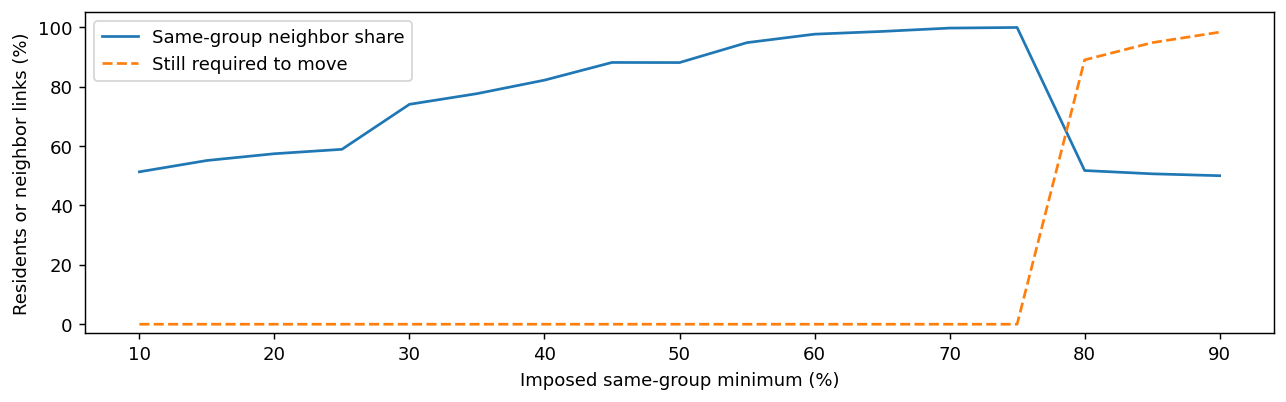

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(classic.index, classic.similar_mean, label='Same-group neighbor share')
ax.plot(classic.index, classic.relocate_mean, '--', label='Still required to move')
ax.set(xlabel='Imposed same-group minimum (%)',
       ylabel='Residents or neighbor links (%)', ylim=(-3, 105))
ax.legend()
fig.tight_layout()
fig.savefig('classic_mixing_settling.pdf', bbox_inches='tight')
plt.show()


## 4. Answer
**The rule produces mixing that settles at low minimums, but not across all settings.**

- At **10%**, all 30 runs settle and mean same-group similarity is **51.3%**.
- At the proposed **30%**, all 30 runs settle, but similarity reaches **74.1%**. At **70–75%**, it reaches **99.7–99.9%** despite every run settling.
- At **80–90%**, similarity returns to **50.0–51.8%**, but no run settles by the cap; **89.0–98.4%** of residents still need to move.

**Stopping relocation does not ensure mixing, and a mixed-looking endpoint does not ensure settling.**

## Sources
[Course data and model](https://github.com/DACSS-Complexity/s6_From_Micromotives_to_Macrobehavior/tree/main/exercise): `policy-relocation-table.csv` and `Segregation_policy.nlogox`. Model lineage: Schelling (1969), Wilensky (1997), and course adaptation by Prof. Jose Magallanes. The uploaded model and analysis data must be versioned together for full reproducibility.